# Tarefa 1 — Dataset AI_Human:

**Documentação do dataset** 
- Fonte/proveniência: _<URL do repositório/https://drive.google.com/file/d/16LvnJSI7on6e4wMec5m_2edSnc4zko8c/view>_ 
- Língua: inglês | Dimensão: 487 235 exemplos | Classes: `generated` 0=human / 1=ai
- Balanceamento: ~63% human / ~37% ai



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pre_proces import preprocess_text   # <- partilhado com o Predicao.py

sns.set_style("whitegrid")

## 1. Leitura e tipos

In [2]:
df = pd.read_csv("AI_Human.csv")
df["generated"] = df["generated"].astype(int)     # labels 0/1 inteiros
df.info()
df.head()
if "generated" not in df.columns and "label" in df.columns:
    df["generated"] = df["label"].astype(int)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 487235 entries, 0 to 487234
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   text       487235 non-null  object
 1   generated  487235 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 7.4+ MB


## 2. EDA — balanceamento, qualidade e comprimento

Balanceamento:
generated
0    305797
1    181438
Name: count, dtype: int64
Duplicados exatos: 0
Textos vazios: 4


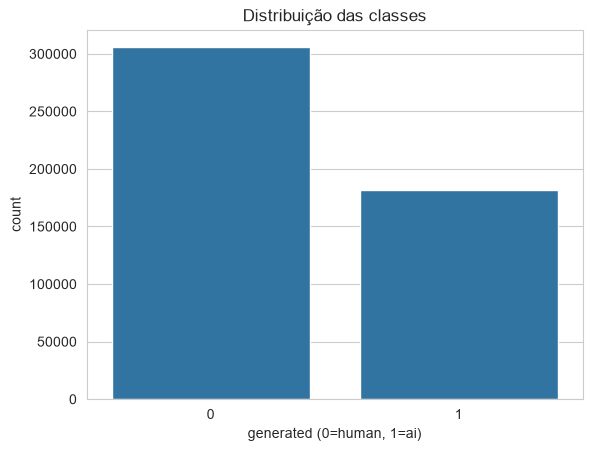

In [3]:
print("Balanceamento:"); print(df["generated"].value_counts())
print("Duplicados exatos:", df.duplicated(subset=["text"]).sum())
print("Textos vazios:", (df["text"].str.strip().str.len() == 0).sum())

sns.countplot(x="generated", data=df)
plt.title("Distribuição das classes")
plt.xlabel("generated (0=human, 1=ai)")
plt.show()

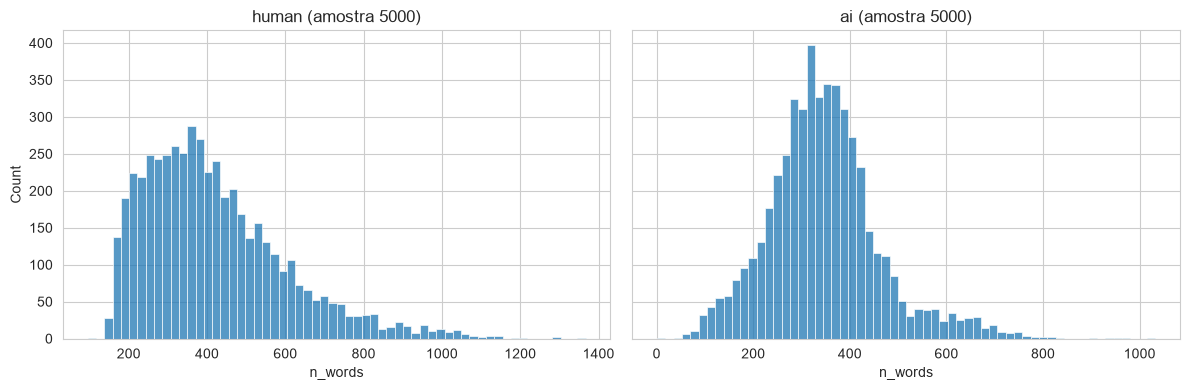

                mean    50%     max
generated                          
0          421.98518  389.0  1668.0
1          344.40653  337.0  1238.0


In [4]:

df["n_words"] = df["text"].str.split().str.len()   # comprimento em PALAVRAS

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for cls, nome in ((0, "human"), (1, "ai")):
    vals = df.loc[df.generated == cls, "n_words"].sample(5000, random_state=42)
    sns.histplot(vals, bins=60, ax=ax[cls]).set_title(f"{nome} (amostra 5000)")
plt.tight_layout(); plt.show()
print(df.groupby("generated")["n_words"].describe()[["mean", "50%", "max"]])

## 3. Pré-processamento 

Ordem: lowercase → expansão de contrações → remoção de pontuação → stopwords.


In [5]:
df["text_clean"] = df["text"].map(preprocess_text)
print("ANTES:", df["text"][0][:120], "...")
print("DEPOIS:", df["text_clean"][0][:120], "...")

ANTES: Cars. Cars have been around since they became famous in the 1900s, when Henry Ford created and built the first ModelT. C ...
DEPOIS: cars cars around since became famous 1900s henry ford created built modelt cars played major role every lives since star ...


## 4. Split estratificado 70/15/15 (treino / validação / teste)

In [6]:
from sklearn.model_selection import train_test_split

x = df["text_clean"]; y = df["generated"]
x_tv, x_te, y_tv, y_te = train_test_split(x, y, test_size=0.15, stratify=y, random_state=42)
x_tr, x_va, y_tr, y_va = train_test_split(x_tv, y_tv, test_size=0.1765, stratify=y_tv, random_state=42)
print(len(x_tr), len(x_va), len(x_te))
print("train:", y_tr.value_counts().to_dict(), "| val:", y_va.value_counts().to_dict(), "| test:", y_te.value_counts().to_dict())

341051 73098 73086
train: {0: 214049, 1: 127002} | val: {0: 45878, 1: 27220} | test: {0: 45870, 1: 27216}


## 5. TF-IDF — **fit apenas no treino** (sem leakage)

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(norm="l1")          # opcional: max_features=200000 p/ velocidade
X_tr = tfidf.fit_transform(x_tr)            # FIT só no treino
X_va = tfidf.transform(x_va)
X_te = tfidf.transform(x_te)
print(X_tr.shape, X_va.shape, X_te.shape)

(341051, 239208) (73098, 239208) (73086, 239208)


## 6. Modelos — seleção pela VALIDACÃO

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

lr = LogisticRegression(penalty="l2", C=1.0, tol=0.1, max_iter=1000)
lr.fit(X_tr, y_tr)
print("LR  val acc:", accuracy_score(y_va, lr.predict(X_va)))

svm = LinearSVC(penalty="l1", C=1.0, dual=False, loss="squared_hinge", tol=0.1)
svm.fit(X_tr, y_tr)
print("SVM val acc:", accuracy_score(y_va, svm.predict(X_va)))
print(classification_report(y_va, svm.predict(X_va)))

C:\Users\donex\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


LR  val acc: 0.6276231907849736
SVM val acc: 0.9930777859859367
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     45878
           1       0.99      0.99      0.99     27220

    accuracy                           0.99     73098
   macro avg       0.99      0.99      0.99     73098
weighted avg       0.99      0.99      0.99     73098



In [9]:
# Avaliação final no TESTE (uma única vez), com o melhor modelo da validação
best = svm if accuracy_score(y_va, svm.predict(X_va)) >= accuracy_score(y_va, lr.predict(X_va)) else lr
print("Melhor modelo:", type(best).__name__)
print("TESTE acc:", accuracy_score(y_te, best.predict(X_te)))
print(classification_report(y_te, best.predict(X_te)))

Melhor modelo: LinearSVC
TESTE acc: 0.992857729250472
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     45870
           1       0.99      0.99      0.99     27216

    accuracy                           0.99     73086
   macro avg       0.99      0.99      0.99     73086
weighted avg       0.99      0.99      0.99     73086



## 7. Artefacto final (refit em train+val) e gravação

 Para a app, refitamos vectorizador+modelo em train+val.

In [10]:
import pickle

x_final = pd.concat([x_tr, x_va]); y_final = pd.concat([y_tr, y_va])
tfidf_final = TfidfVectorizer(norm="l1")
X_final = tfidf_final.fit_transform(x_final)
best_final = type(best)(**best.get_params())
best_final.fit(X_final, y_final)

with open("clf.pkl", "wb") as f: pickle.dump(best_final, f)
with open("tfidf.pkl", "wb") as f: pickle.dump(tfidf_final, f)

metadata = {
    "dataset": "AI_Human.csv",
    "preprocess": "preprocess.py::preprocess_text (v1)",
    "model": type(best_final).__name__,
    "splits": {"train": len(x_tr), "val": len(x_va), "test": len(x_te)},
    "test_accuracy": float(accuracy_score(y_te, best.predict(X_te))),
}
with open("metadata.json", "w") as f: json.dump(metadata, f, indent=2)
print("Gravados: clf.pkl, tfidf.pkl, metadata.json")

Gravados: clf.pkl, tfidf.pkl, metadata.json



# 8. Submissão externa — dataset externo


O ficheiro `dataset_externo` é utilizado apenas para inferência final. Não é usado para treino, validação, escolha de hiperparâmetros ou cálculo de métricas.

Fluxo: `dataset_externo` → pré-processamento → TF-IDF final → modelo `best_final` → labels `Human`/`AI` → CSV de submissão.


In [11]:
# 9.1 Configuração da submissão
# Esta célula é nova; as células originais não foram alteradas.

from pathlib import Path

GROUP_NUMBER = "7"  #  número real do grupo
SUBMISSION_NUMBER = "1"

INPUT_PATH = Path("dataset3_inputs.csv")
SUBMISSION_DIR = Path("Submissao1")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

print("Pasta de trabalho:", Path.cwd())
print("Ficheiro de inputs:", INPUT_PATH.resolve())
print("Pasta de saída:", SUBMISSION_DIR.resolve())


Pasta de trabalho: c:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1
Ficheiro de inputs: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\dataset3_inputs.csv
Pasta de saída: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1


In [12]:
# 9.2 Leitura do dataset externo

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Ficheiro não encontrado: {INPUT_PATH.resolve()}. "
        "Coloque dataset3_inputs.csv na mesma pasta do notebook."
    )

# Verificação se o ficheiro usa ponto e vírgula como separador.
inputs_df = pd.read_csv(
    INPUT_PATH,
    sep=";",
    encoding="utf-8-sig"
)

print("Dimensão:", inputs_df.shape)
print("Colunas:", list(inputs_df.columns))
print(inputs_df.head(3).to_string(index=False))


Dimensão: (100, 2)
Colunas: ['ID', 'Text']
  ID                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 Text
D3-1               

In [13]:
# 9.3 Validação dos números de exemplos

if len(inputs_df) != 100:
    raise ValueError(
        f"Esperavam-se 100 exemplos, mas foram encontrados {len(inputs_df)}."
    )

if list(inputs_df.columns) != ["ID", "Text"]:
    raise ValueError(
        "As colunas devem ser exactamente ['ID', 'Text']. "
        f"Foram encontradas: {list(inputs_df.columns)}"
    )

if inputs_df["ID"].duplicated().any():
    raise ValueError("Existem IDs duplicados.")

if inputs_df["ID"].isna().any():
    raise ValueError("Existem IDs vazios.")

if inputs_df["Text"].isna().any():
    raise ValueError("Existem textos nulos.")

if inputs_df["Text"].astype(str).str.strip().eq("").any():
    raise ValueError("Existem textos vazios.")

print("Dataset do professor validado com sucesso.")
print("Número de exemplos:", len(inputs_df))
print("IDs únicos:", inputs_df["ID"].nunique())
print("Primeiro ID:", inputs_df["ID"].iloc[0])
print("Último ID:", inputs_df["ID"].iloc[-1])


Dataset do professor validado com sucesso.
Número de exemplos: 100
IDs únicos: 100
Primeiro ID: D3-1
Último ID: D3-100


In [14]:
# 9.4 Aplicar o mesmo pré-processamento utilizado no treino

external_texts = (
    inputs_df["Text"]
    .astype(str)
    .map(preprocess_text)
)

print("Pré-processamento concluído para", len(external_texts), "textos.")
print("\nTexto original:\n", inputs_df["Text"].iloc[0][:250])
print("\nTexto pré-processado:\n", external_texts.iloc[0][:250])


Pré-processamento concluído para 100 textos.

Texto original:
 String theory is a broad and varied subject that attempts to address a number of deep questions of fundamental physics. String theory has contributed a number of advances to mathematical physics, which have been applied to a variety of problems in bl

Texto pré-processado:
 string theory broad varied subject attempts address number deep questions fundamental physics string theory contributed number advances mathematical physics applied variety problems black hole physics early universe cosmology nuclear physics condense


In [15]:
# 9.5 Transformar os textos usando o TF-IDF final e gerar previsões

# tfidf_final e best_final foram criados na célula original de refit.
X_external = tfidf_final.transform(external_texts)

predictions_external = best_final.predict(X_external)

print("Dimensão da matriz externa:", X_external.shape)
print("Número de previsões:", len(predictions_external))
print("Valores numéricos produzidos:", sorted(set(predictions_external)))


Dimensão da matriz externa: (100, 267847)
Número de previsões: 100
Valores numéricos produzidos: [np.int64(0), np.int64(1)]


In [16]:
# 9.6 Converter as previsões para as labels exactas exigidas

labels_external = np.where(
    predictions_external == 1,
    "AI",
    "Human"
)

if len(labels_external) != 100:
    raise ValueError(
        f"Foram produzidas {len(labels_external)} previsões em vez de 100."
    )

if not set(labels_external).issubset({"Human", "AI"}):
    raise ValueError(
        f"Labels inválidas: {set(labels_external)}"
    )

print("Labels válidas.")
print(pd.Series(labels_external).value_counts())


Labels válidas.
AI       64
Human    36
Name: count, dtype: int64


In [17]:
# 9.7 Criar o ficheiro CSV de submissão

submission_df = inputs_df.copy()
submission_df["output"] = labels_external

submission_filename = (
    f"submissao1-grupo{GROUP_NUMBER}-s{SUBMISSION_NUMBER}.csv"
)
submission_path = SUBMISSION_DIR / submission_filename

submission_df.to_csv(
    submission_path,
    sep=";",
    index=False,
    encoding="utf-8"
)

print("Ficheiro criado:")
print(submission_path.resolve())
print(submission_df.head(3).to_string(index=False))
print("\nDistribuição das previsões:")
print(submission_df["output"].value_counts())


Ficheiro criado:
C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1\submissao1-grupo7-s1.csv
  ID                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [18]:
# 9.8 Validação final do ficheiro gravado

saved_submission = pd.read_csv(
    submission_path,
    sep=";",
    encoding="utf-8-sig"
)

assert len(saved_submission) == 100
assert list(saved_submission.columns) == ["ID", "Text", "output"]
assert saved_submission["ID"].is_unique
assert not saved_submission["output"].isna().any()
assert set(saved_submission["output"]).issubset({"Human", "AI"})

print("==============================================")
print("FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO")
print("==============================================")
print("Caminho:", submission_path.resolve())
print("Linhas:", len(saved_submission))
print("Colunas:", list(saved_submission.columns))
print(saved_submission["output"].value_counts())


FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO
Caminho: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1\submissao1-grupo7-s1.csv
Linhas: 100
Colunas: ['ID', 'Text', 'output']
output
AI       64
Human    36
Name: count, dtype: int64
